# Catch-Up Sleep and Depressive Symptoms
## INFO 2950 Project - Phase III
**Eric Wang and Mary Yang**

### Running This Notebook
Keep this notebook in the repository root, alongside `data`. Run [data_cleaning.ipynb](https://github.com/EricWangXX/INFO-2950-Project/blob/main/data_cleaning.ipynb) to create the cleaned files, then restart this notebook's kernel and run all cells. This notebook reads the cleaned data and performs the analyses without further exclusions.

Required packages: numpy, pandas, statsmodels, matplotlib, and IPython; the cleaning notebook also uses DuckDB. **All analyses are unweighted.**

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

df = pd.read_csv("data/processed/phase3/03_analysis_ready.csv")
sample_counts = pd.read_csv("data/processed/phase3/sample_counts.csv", index_col=0)

# Code recorded sex for the model without modifying the cleaned dataset.
analysis = df.assign(female=(df["RIAGENDR"] == 2).astype(int))
display(pd.DataFrame({"Rows": [len(df)], "Columns": [df.shape[1]]}))

,Rows,Columns
0,1252,19


## Introduction
We study the association between usual workday and non-workday sleep differences and depressive symptom scores among adults reporting short workday sleep in NHANES 2017–2018. Catch-up sleep is non-workday sleep minus workday sleep, in hours; it can be negative.

### Research Question
Among adults in NHANES 2017–2018 who usually sleep fewer than seven hours on workdays, is catch-up sleep duration (non-workday minus workday sleep duration) associated with depressive symptom scores?

This question examines an adjusted sleep–symptom association within an already short-sleeping sample. Related NHANES research motivates considering the overall association and possible differences by recorded sex ([Luo et al., 2024](https://doi.org/10.1016/j.jad.2024.03.008)). We retain both Phase II analyses and separately identify the formal sex-difference test added in Phase III.

**Main finding:** Each additional catch-up hour was associated with a 0.286-point lower predicted PHQ-9 score after adjustment (four-test Bonferroni p = 0.0011). The model explained about 6% of in-sample score variation. Both sex-specific estimates were negative, but the added formal comparison did not establish a difference between their slopes. These are unweighted, model-based associations, not causal or national-population conclusions.

## Data Description and Cleaning

Our analysis-ready dataset contains 1,252 rows and 19 columns. Each row represents a NHANES 2017–2018 participant aged 18 or older who reported fewer than seven hours of workday sleep, had usable workday and non-workday sleep durations, and provided complete responses to nine depression symptom questions. We created this dataset to examine whether catch-up sleep duration is associated with depressive symptom scores.

### Variables

| Columns | Description |
|---|---|
| SEQN | Unique participant identifier |
| SLD012, SLD013 | Usual workday and non-workday sleep duration, in hours |
| catch_up_sleep | Non-workday minus workday sleep duration, in hours |
| DPQ010–DPQ090 | Nine items measuring depressive symptom frequency over the past two weeks, each scored 0–3 |
| depression_score | Sum of all nine items, with a possible range of 0–27; higher scores indicate more reported symptoms |
| RIDAGEYR, RIAGENDR | Age and recorded sex |
| WTMEC2YR, SDMVPSU, SDMVSTRA | Examination weight, sampling unit, and stratum |

DPQ010-DPQ090 form the nine-item Patient Health Questionnaire (PHQ-9), scored from 0 to 27. DPQ100 measures difficulty with daily functioning and is not included in the nine-item total. We analyze the continuous symptom score rather than defining a binary depression outcome (CDC/NCHS, 2020b).

### Sources and Collection

NHANES was created by CDC/NCHS to assess the health and nutritional status of the U.S. civilian noninstitutionalized population. Participants received information about the survey’s purposes, procedures, and confidentiality through its informed-consent process (CDC/NCHS, 2024; n.d.-a). Our project uses publicly released data; we did not recruit or contact participants.

We downloaded the 2017–2018 Sleep Disorders (SLQ_J), Depression Screener (DPQ_J), and Demographic Variables and Sample Weights (DEMO_J) SAS transport files (CDC/NCHS, 2020a–c). Sleep questions were asked at home; depression questions were asked at the mobile examination center. SLD012 and SLD013 were derived by NHANES from reported usual sleep and wake times and rounded to half-hour increments; they describe the main sleeping period, not necessarily total daily sleep.

### Preprocessing and Sample Selection

Using pandas and DuckDB, we checked that SEQN was unique and nonmissing in each file, then merged the datasets using the sleep dataset as the starting sample. We corrected near-zero numerical representations of zero symptom scores and treated responses outside 0–3 as missing. Depression totals were calculated only when all nine responses were valid.

We retained adults with workday sleep below seven hours and complete depression scores. We excluded missing sleep durations and codes 2 and 14, which represent less than three hours and at least fourteen hours rather than specific durations. Catch-up sleep was calculated as SLD013 minus SLD012, retaining negative differences. Original files were preserved, and intermediate datasets and sample counts were saved.

Survey sampling, voluntary participation, questionnaire eligibility, and nonresponse influence which observations are available. Participants requiring proxy responses were ineligible for the depression questionnaire. Our additional exclusions further restrict the final sample, which should not automatically be treated as representative of all U.S. adults.

We use the sampling-unit and stratum columns to account approximately for participants sharing a sampling cluster. We retain but do not apply the examination weight, following our original unweighted plan. The analysis therefore does not provide nationally representative estimates (CDC/NCHS, n.d.-b).

### Data Access and Documentation

Raw data: [Original NHANES 2017–2018 data files](https://github.com/EricWangXX/INFO-2950-Project/tree/main/data/raw).

Official documentation: [NHANES overview](https://www.cdc.gov/nchs/nhanes/about/index.html), [2017–2018 consent documents](https://wwwn.cdc.gov/nchs/nhanes/continuousnhanes/documents.aspx?BeginYear=2017), [SLQ_J](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/SLQ_J.htm), [DPQ_J](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DPQ_J.htm), and [DEMO_J](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DEMO_J.htm).

### Separate Cleaning Workflow and Access
The cleaning rules above are implemented in [data_cleaning.ipynb](https://github.com/EricWangXX/INFO-2950-Project/blob/main/data_cleaning.ipynb). This notebook reads [the analysis-ready CSV](https://github.com/EricWangXX/INFO-2950-Project/blob/main/data/processed/phase3/03_analysis_ready.csv) and [sample counts](https://github.com/EricWangXX/INFO-2950-Project/blob/main/data/processed/phase3/sample_counts.csv). The cleaning notebook, intermediate files, analysis-ready data, and sample counts are available in the project GitHub repository. Download the complete repository to preserve the folder structure when reproducing the analysis.

The table below reports the number of participants remaining at each cleaning step.

In [2]:
display(sample_counts)

,Participants
Merged sleep sample,6161
Adults aged 18+,5856
Exact sleep durations available,5726
Workday sleep below 7 hours,1402
Complete depression score,1252


## Preregistration Statements
The two statements below are copied unchanged from our Phase II final notebook, with the literature background carried forward. Phase II planned an overall regression and a descriptive comparison of male and female regressions.

**The significance procedures were added in Phase III.** The direct sex-difference test was added after examining the original regression results and is reported as an exploratory extension.

### Background for the Hypotheses
[Luo et al. (2024)](https://pubmed.ncbi.nlm.nih.gov/38452941/) analyzed NHANES 2017–2020. Their overall fully adjusted associations were not statistically significant, although they reported an L-shaped pattern, negative associations within 0–2 hours of catch-up sleep, and stronger associations among men and short weekday sleepers. This motivates examining our overall association and sex-specific estimates without assuming that more catch-up sleep is uniformly associated with fewer symptoms. Because the datasets overlap, our project is a related secondary analysis rather than an independent replication. Our selected sample and modeling choices also differ from their survey-design analyses. This background was included in the revised Phase II report; the two original preregistration statements below remain unchanged.

## Preregistration Statement 1

**Hypothesis:** Among adults reporting fewer than seven hours of workday sleep, longer catch-up sleep duration is associated with lower depressive symptom scores.

**Proposed analysis:** We will fit an unweighted multiple linear regression predicting depression_score from catch_up_sleep, adjusting for age, sex, and workday sleep duration. We will examine the sign and magnitude of the catch_up_sleep coefficient; our hypothesis predicts a negative coefficient. Results will describe associations in the selected sample, not nationally representative estimates or causal effects.

$\beta_{\mathrm{catchup}}$, the catch_up_sleep coefficient, represents the difference in predicted depressive symptom score associated with one additional hour of non-workday sleep, holding workday sleep duration, age, and recorded sex constant.

## Preregistration Statement 2

**Hypothesis:** The association between catch-up sleep duration and depressive symptom scores differs between male and female participants.

**Proposed analysis:** We will fit separate unweighted multiple linear regressions for male and female participants, predicting depression_score from catch_up_sleep and adjusting for age and workday sleep duration. We will descriptively compare the direction and magnitude of the catch_up_sleep coefficients. This comparison will describe patterns in the selected sample; differences between estimated coefficients alone will not establish a statistically significant sex difference or a population-level difference.
We will report both analyses in our final report regardless of whether the results support our hypotheses.

### Significance Testing: Phase III Addition
We test four quantities against zero: the overall catch-up slope, the male slope, the female slope, and the female-minus-male slope difference. All tests are two-sided; support for Hypothesis 1 also requires a negative overall slope.

**Why adjust standard errors?** Participants in the same NHANES sampling cluster may be related statistically. We use PSU-clustered standard errors to allow for this when calculating confidence intervals and p-values. This is an approximate adjustment, not a complete weighted survey analysis.

**Multiple tests:** We apply Bonferroni correction to the four p-values, `min(4 * p, 1)`, and compare the adjusted values with 0.05. The displayed 95% confidence intervals describe each coefficient separately; decisions use the adjusted p-values.

The original regressions are retained. The added difference test is exploratory because it was chosen after viewing their results. Technical details and ordinary OLS p-values appear in the supplementary methods.

## Data Analysis
### Analysis 1: Adjusted Overall Association
We predict PHQ-9 symptom scores from catch-up sleep, age, recorded sex (`female = 1`, `male = 0`), and workday sleep. We do not also include non-workday sleep because it equals workday sleep plus catch-up sleep.

Each coefficient describes a predicted score difference while holding the other predictors constant. The intercept is not meaningful for a typical participant because it assumes age and workday sleep are zero. The table gives coefficients and cluster-adjusted 95% confidence intervals.

In [3]:
model_all = smf.ols(
    "depression_score ~ catch_up_sleep + RIDAGEYR + female + SLD012",
    data=analysis, missing="raise"
).fit()

# PSU labels repeat between strata, so use their combination as the cluster.
clusters_all = analysis.groupby(["SDMVSTRA", "SDMVPSU"]).ngroup()
cluster_all = model_all.get_robustcov_results(
    cov_type="cluster", groups=clusters_all,
    use_correction=True, df_correction=True, use_t=True
)

def coefficient_table(model, robust_result):
    intervals = robust_result.conf_int(alpha=0.05)
    table = pd.DataFrame({
        "Coefficient": model.params,
        "Cluster SE": robust_result.bse,
        "95% CI lower": intervals[:, 0],
        "95% CI upper": intervals[:, 1],
        "Cluster p (unadjusted)": robust_result.pvalues
    })
    return table

coef_all = coefficient_table(model_all, cluster_all)
display(coef_all[["Coefficient", "95% CI lower", "95% CI upper"]].round(3))

,Coefficient,95% CI lower,95% CI upper
Intercept,10.592,8.241,12.943
catch_up_sleep,-0.286,-0.427,-0.145
RIDAGEYR,-0.030,-0.046,-0.013
female,0.987,0.472,1.502
SLD012,-0.994,-1.305,-0.684


In [4]:
beta_all = model_all.params["catch_up_sleep"]
ci_all = coef_all.loc["catch_up_sleep", ["95% CI lower", "95% CI upper"]]
direction = "lower" if beta_all < 0 else "higher"
display(Markdown(
    f"**Summarize:** Holding age, recorded sex, and workday sleep constant, "
    f"one additional hour of catch-up sleep is associated with a "
    f"{abs(beta_all):.3f}-point {direction} predicted symptom score "
    f"(cluster-adjusted 95% CI: "
    f"{ci_all.iloc[0]:.3f} to {ci_all.iloc[1]:.3f}). With workday sleep fixed, "
    "this is also one additional hour of non-workday sleep. "
    "This is an adjusted association, not an effect of changing someone's sleep. "
    "The significance test, corrected for multiple comparisons, appears below."
))

**Summarize:** Holding age, recorded sex, and workday sleep constant, one additional hour of catch-up sleep is associated with a 0.286-point lower predicted symptom score (cluster-adjusted 95% CI: -0.427 to -0.145). With workday sleep fixed, this is also one additional hour of non-workday sleep. This is an adjusted association, not an effect of changing someone's sleep. The significance test, corrected for multiple comparisons, appears below.

### Analysis 2: Descriptive Comparison by Recorded Sex
We fit separate male and female regressions, adjusting for age and workday sleep. This follows the original Phase II plan. Comparing their coefficients describes the sample; a direct test is needed to assess whether the slopes differ.

In [5]:
male = analysis.loc[analysis["RIAGENDR"] == 1].copy()
female = analysis.loc[analysis["RIAGENDR"] == 2].copy()
formula_group = "depression_score ~ catch_up_sleep + RIDAGEYR + SLD012"
model_male = smf.ols(formula_group, data=male, missing="raise").fit()
model_female = smf.ols(formula_group, data=female, missing="raise").fit()

models = {"Overall": model_all, "Male": model_male, "Female": model_female}
groups = {"Overall": analysis, "Male": male, "Female": female}
robust_models = {"Overall": cluster_all}
for label in ["Male", "Female"]:
    cluster_ids = groups[label].groupby(["SDMVSTRA", "SDMVPSU"]).ngroup()
    robust_models[label] = models[label].get_robustcov_results(
        cov_type="cluster", groups=cluster_ids,
        use_correction=True, df_correction=True, use_t=True
    )

rows = []
for label, model in models.items():
    position = model.params.index.get_loc("catch_up_sleep")
    robust = robust_models[label]
    interval = robust.conf_int(alpha=0.05)[position]
    rows.append({
        "Model": label, "N": int(model.nobs),
        "Clusters": groups[label].groupby(["SDMVSTRA", "SDMVPSU"]).ngroups,
        "Coefficient": model.params["catch_up_sleep"],
        "95% CI lower": interval[0], "95% CI upper": interval[1],
        "OLS p": model.pvalues["catch_up_sleep"],
        "Cluster p": robust.pvalues[position]
    })
results = pd.DataFrame(rows).set_index("Model")
display(results.loc[["Male", "Female"],
    ["N", "Coefficient", "95% CI lower", "95% CI upper"]].round(3))

,N,Coefficient,95% CI lower,95% CI upper
Model,,,,
Male,694,-0.245,-0.428,-0.062
Female,558,-0.346,-0.556,-0.136


In [6]:
beta_male = model_male.params["catch_up_sleep"]
beta_female = model_female.params["catch_up_sleep"]
display(Markdown(
    f"**Summarize:** The adjusted catch-up coefficient is {beta_male:.3f} "
    f"score points/hour among {len(male):,} male participants and "
    f"{beta_female:.3f} among {len(female):,} female participants. "
    f"The estimated female-minus-male difference is "
    f"{beta_female - beta_male:.3f} score points/hour. "
    "The difference between these estimates alone is not a "
    "significance test. We test it in the added analysis below."
))

**Summarize:** The adjusted catch-up coefficient is -0.245 score points/hour among 694 male participants and -0.346 among 558 female participants. The estimated female-minus-male difference is -0.101 score points/hour. The difference between these estimates alone is not a significance test. We test it in the added analysis below.

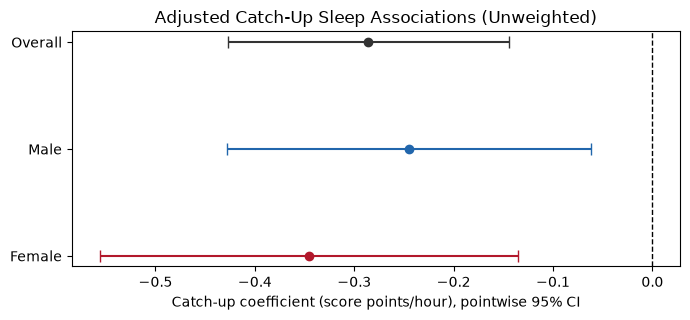

In [7]:
# Compare adjusted estimates and uncertainty, not a test of sex differences.
fig, ax = plt.subplots(figsize=(7, 3.3))
for position, (label, row) in enumerate(results.iterrows()):
    ax.errorbar(
        row["Coefficient"], position,
        xerr=[[row["Coefficient"] - row["95% CI lower"]],
              [row["95% CI upper"] - row["Coefficient"]]],
        fmt="o", capsize=4, color=["#333333", "#2166ac", "#b2182b"][position]
    )
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_yticks(range(len(results)), results.index)
ax.invert_yaxis()
ax.set_xlabel("Catch-up coefficient (score points/hour), pointwise 95% CI")
ax.set_title("Adjusted Catch-Up Sleep Associations (Unweighted)")
plt.tight_layout()
plt.show()

**Figure interpretation:** All three estimated slopes are negative, with 95% intervals below zero. The female estimate is more negative, but this graph alone does not establish a sex difference. The intervals use cluster-adjusted standard errors; significance decisions below also account for multiple tests.

### Added Analysis: Do the Male and Female Slopes Differ?
**This exploratory test was added in Phase III after viewing the original regressions.** We combine those two regressions into one model so that we can directly test their difference:

`depression_score ~ female * (catch_up_sleep + RIDAGEYR + SLD012)`

Each sex keeps its own intercept and predictor slopes, so the fitted relationships match the original separate regressions. The `female:catch_up_sleep` coefficient equals the female catch-up slope minus the male slope. We test whether this difference is zero, using the same standard-error adjustment and four-test Bonferroni correction.

In [8]:
# Fully interacted model: the original group regressions in one model.
model_difference = smf.ols(
    "depression_score ~ female * (catch_up_sleep + RIDAGEYR + SLD012)",
    data=analysis, missing="raise"
).fit()
cluster_difference = model_difference.get_robustcov_results(
    cov_type="cluster", groups=clusters_all,
    use_correction=True, df_correction=True, use_t=True
)
term_difference = "female:catch_up_sleep"
position_difference = model_difference.params.index.get_loc(term_difference)
beta_difference = model_difference.params[term_difference]
ci_difference = cluster_difference.conf_int(alpha=0.05)[position_difference]

# Verify that the pooled interaction measures the original slope difference.
assert np.isclose(beta_difference, beta_female - beta_male)

difference_row = pd.DataFrame([{
    "N": int(model_difference.nobs), "Clusters": clusters_all.nunique(),
    "Coefficient": beta_difference,
    "95% CI lower": ci_difference[0], "95% CI upper": ci_difference[1],
    "OLS p": model_difference.pvalues[term_difference],
    "Cluster p": cluster_difference.pvalues[position_difference]
}], index=["Female minus male"])
inference_results = pd.concat([results, difference_row])
inference_results.index.name = "Test"
inference_results["Bonferroni p"] = np.minimum(
    4 * inference_results["Cluster p"], 1.0
)
inference_results["Reject zero"] = inference_results["Bonferroni p"] < 0.05

display(inference_results.loc[["Female minus male"], [
    "Coefficient", "95% CI lower", "95% CI upper", "Bonferroni p"
]].style.format({
    "Coefficient": "{:.3f}", "95% CI lower": "{:.3f}",
    "95% CI upper": "{:.3f}", "Bonferroni p": "{:.3g}"
}))
difference_p = inference_results.loc["Female minus male", "Bonferroni p"]
reject_difference = bool(inference_results.loc["Female minus male", "Reject zero"])
decision_difference = "reject" if reject_difference else "fail to reject"
if reject_difference:
    difference_conclusion = (
        "The added test finds evidence of a slope difference; "
        "its exploratory timing and survey limitations still apply."
    )
else:
    difference_conclusion = (
        "The added test does not establish a sex difference. "
        "Failing to reject does not demonstrate that the slopes are equal."
    )
display(Markdown(
    f"**Added-analysis result:** The female-minus-male slope difference is "
    f"{beta_difference:.3f} score points/hour (cluster-adjusted 95% CI "
    f"{ci_difference[0]:.3f} to {ci_difference[1]:.3f}). "
    f"We {decision_difference} a zero slope difference "
    f"(four-test Bonferroni p = {difference_p:.3f}). {difference_conclusion}"
))

,Coefficient,95% CI lower,95% CI upper,Bonferroni p
Test,,,,
Female minus male,-0.101,-0.373,0.171,1


**Added-analysis result:** The female-minus-male slope difference is -0.101 score points/hour (cluster-adjusted 95% CI -0.373 to 0.171). We fail to reject a zero slope difference (four-test Bonferroni p = 1.000). The added test does not establish a sex difference. Failing to reject does not demonstrate that the slopes are equal.

### Prediction Examples
Consider participants aged 40 with six hours of workday sleep and zero, one, or two catch-up hours. The table compares predictions from the overall model and the corresponding sex-specific model. These are predicted symptom scores, not diagnoses or effects of changing sleep.

In [9]:
examples = pd.DataFrame({
    "RIDAGEYR": [40] * 6,
    "SLD012": [6] * 6,
    "female": [0, 0, 0, 1, 1, 1],
    "catch_up_sleep": [0, 1, 2, 0, 1, 2]
})
prediction_table = pd.DataFrame({
    "Recorded sex": examples["female"].map({0: "Male", 1: "Female"}),
    "Age": examples["RIDAGEYR"],
    "Workday hours": examples["SLD012"],
    "Non-workday hours": examples["SLD012"] + examples["catch_up_sleep"],
    "Overall-model score": model_all.predict(examples),
    "Sex-specific score": np.nan
})
for value, model in [(0, model_male), (1, model_female)]:
    mask = examples["female"] == value
    prediction_table.loc[mask, "Sex-specific score"] = model.predict(examples.loc[mask])
display(prediction_table.round(3))
display(Markdown(
    f"**Predict:** For the hypothetical male participant above, the overall "
    f"model predicts {prediction_table.iloc[0]['Overall-model score']:.2f} "
    f"points with no catch-up sleep and "
    f"{prediction_table.iloc[1]['Overall-model score']:.2f} points with "
    "one catch-up hour. The change equals the overall catch-up coefficient. "
    "The separate models allow different age and workday-sleep slopes as "
    "well as different catch-up slopes, so their predictions need not equal "
    "the overall model's predictions."
))

,Recorded sex,Age,Workday hours,Non-workday hours,Overall-model score,Sex-specific score
0,Male,40,6,6,3.442,3.307
1,Male,40,6,7,3.156,3.062
2,Male,40,6,8,2.870,2.817
3,Female,40,6,6,4.429,4.626
4,Female,40,6,7,4.143,4.280
5,Female,40,6,8,3.857,3.934


**Predict:** For the hypothetical male participant above, the overall model predicts 3.44 points with no catch-up sleep and 3.16 points with one catch-up hour. The change equals the overall catch-up coefficient. The separate models allow different age and workday-sleep slopes as well as different catch-up slopes, so their predictions need not equal the overall model's predictions.

### Oddities, Outliers, and Model Diagnostics
Residuals are observed minus predicted symptom scores. The plots below check whether the linear mean model leaves structure or changing spread, and whether a normal-error approximation is plausible. All three models use the complete eligible sample for their respective group; no cases are dropped because of these diagnostics.

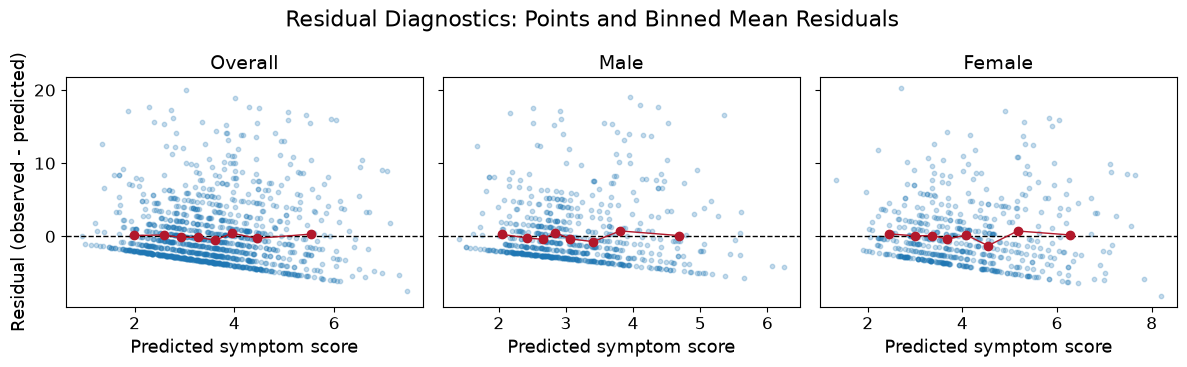

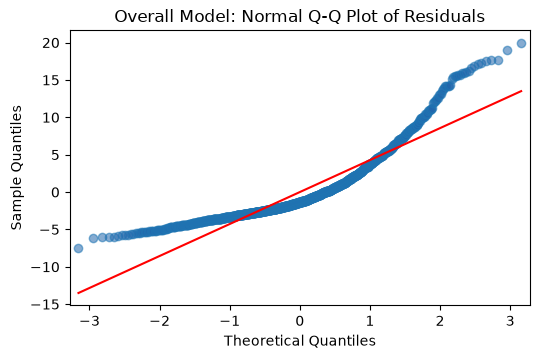

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7), sharey=True)
diagnostics = {}
for ax, (label, model) in zip(axes, models.items()):
    diagnostic = pd.DataFrame({
        "fitted": model.fittedvalues, "residual": model.resid
    })
    diagnostics[label] = diagnostic
    ax.scatter(diagnostic["fitted"], diagnostic["residual"], s=10, alpha=0.25)
    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    # Mean residuals in fitted-value bins reveal broad structure without changing the model.
    bins = pd.qcut(diagnostic["fitted"], q=8, duplicates="drop")
    bin_means = diagnostic.groupby(bins, observed=True)[["fitted", "residual"]].mean()
    ax.plot(bin_means["fitted"], bin_means["residual"], "o-", color="#b2182b", linewidth=1)
    ax.set_title(label, fontsize=14)
    ax.set_xlabel("Predicted symptom score", fontsize=13)
    ax.tick_params(labelsize=12)
axes[0].set_ylabel("Residual (observed - predicted)", fontsize=13)
fig.suptitle("Residual Diagnostics: Points and Binned Mean Residuals", fontsize=16)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(5.5, 3.7))
sm.qqplot(model_all.resid, line="s", ax=ax, markerfacecolor="#2166ac", alpha=0.55)
ax.set_title("Overall Model: Normal Q-Q Plot of Residuals")
plt.tight_layout()
plt.show()

In [11]:
fit_rows = []
for label, model in models.items():
    fit_rows.append({
        "Model": label,
        "R-squared (in sample)": model.rsquared,
        "RMSE (in sample)": np.sqrt(np.mean(model.resid ** 2)),
        "Minimum fitted score": model.fittedvalues.min(),
        "Maximum fitted score": model.fittedvalues.max(),
        "Fitted below 0": int((model.fittedvalues < 0).sum()),
        "Fitted above 27": int((model.fittedvalues > 27).sum())
    })
fit_table = pd.DataFrame(fit_rows).set_index("Model")
display(fit_table.round(3))

# Inspect the five largest absolute residuals; retain these participants in all models.
largest = model_all.resid.abs().nlargest(5).index
outlier_table = analysis.loc[largest, [
    "SEQN", "depression_score", "catch_up_sleep", "RIDAGEYR", "RIAGENDR", "SLD012"
]].copy()
outlier_table["Predicted score"] = model_all.fittedvalues.loc[largest]
outlier_table["Residual"] = model_all.resid.loc[largest]
display(outlier_table.round(3))

,R-squared (in sample),RMSE (in sample),Minimum fitted score,Maximum fitted score,Fitted below 0,Fitted above 27
Model,,,,,,
Overall,0.060,4.278,0.943,7.452,0,0
Male,0.036,4.205,1.406,6.242,0,0
Female,0.069,4.351,1.330,8.191,0,0


,SEQN,depression_score,catch_up_sleep,RIDAGEYR,RIAGENDR,SLD012,Predicted score,Residual
1153,102320.0,23.0,2.5,63.0,2.0,6.0,3.034,19.966
1056,101558.0,23.0,0.0,54.0,1.0,5.0,4.022,18.978
1237,102853.0,22.0,0.0,45.0,1.0,5.0,4.288,17.712
37,93903.0,20.0,0.0,62.0,1.0,6.5,2.294,17.706
626,98165.0,22.0,0.0,55.0,1.0,4.5,4.490,17.510


**Residual plots:** Average residuals are near zero, with some local departures. The diagonal bands partly reflect the score's integer values and lower bound of zero. Large positive residuals show that the models underpredict some high scores.

**Normal Q-Q plot:** The upper tail departs strongly from the line, so normal errors do not describe individual outcomes well. Adjusting standard errors does not fix an incorrect relationship between predictors and the outcome.

**Prediction quality and oddities:** The overall model explains about 6% of score variation, with RMSE 4.28. Its fitted scores range from 0.94 to 7.45. Participant SEQN 102320 has an observed score of 23 but a prediction of 3.03, giving a residual of 19.97. We retain this and the other listed cases because a large residual is not evidence of a data error. These are in-sample checks, not evaluations on new participants.

## Evaluation of Significance
The table uses Bonferroni-adjusted p-values for all four tests. **Reject zero** means the adjusted p-value is below 0.05. For the first three rows, the null is a zero catch-up slope; for the last row, it is no difference between the male and female slopes. The supplementary methods show the p-values before correction.

In [12]:
display(inference_results[[
    "N", "Coefficient", "Bonferroni p", "Reject zero"
]].style.format({
    "N": "{:.0f}", "Coefficient": "{:.3f}", "Bonferroni p": "{:.3g}"
}))

overall_p = inference_results.loc["Overall", "Bonferroni p"]
reject = bool(inference_results.loc["Overall", "Reject zero"])
decision = "reject" if reject else "fail to reject"
if reject and beta_all < 0:
    support = "The result supports a negative association within this model."
elif reject:
    support = "The estimated direction contradicts the original negative-direction hypothesis."
else:
    support = "The original negative-direction hypothesis is not established; this does not imply an exactly zero association."
display(Markdown(
    f"**Hypothesis 1:** We {decision} the zero catch-up slope null under the "
    f"four-test family rule (adjusted p = {overall_p:.4f}). {support} "
    "This is an approximate, unweighted model-based result, "
    "not a national or causal conclusion."
))
display(Markdown(
    "**Hypothesis 2:** The original separate regressions supply the preregistered "
    "descriptive comparison. The added interaction test directly addresses the "
    f"slope difference; we {decision_difference} its zero null "
    f"(four-test adjusted p = {difference_p:.3f}). {difference_conclusion} "
    "This formal test was added after inspecting the original model results."
))

,N,Coefficient,Bonferroni p,Reject zero
Test,,,,
Overall,1252,-0.286,0.00109,True
Male,694,-0.245,0.042,True
Female,558,-0.346,0.0087,True
Female minus male,1252,-0.101,1,False


**Hypothesis 1:** We reject the zero catch-up slope null under the four-test family rule (adjusted p = 0.0011). The result supports a negative association within this model. This is an approximate, unweighted model-based result, not a national or causal conclusion.

**Hypothesis 2:** The original separate regressions supply the preregistered descriptive comparison. The added interaction test directly addresses the slope difference; we fail to reject its zero null (four-test adjusted p = 1.000). The added test does not establish a sex difference. Failing to reject does not demonstrate that the slopes are equal. This formal test was added after inspecting the original model results.

## Conclusions
These findings address associations in the selected sample. They should be read together with the diagnostic and sampling limitations, not as recommendations about sleep or treatment.

In [13]:
display(Markdown(
    f"**Overall association:** Among {len(analysis):,} selected adults, each extra "
    f"hour of non-workday sleep was associated with a {abs(beta_all):.3f}-point "
    f"{direction} predicted PHQ-9 score, holding workday sleep, age, and recorded "
    f"sex constant (95% CI for the coefficient: {ci_all.iloc[0]:.3f} to "
    f"{ci_all.iloc[1]:.3f}; four-test Bonferroni p = {overall_p:.4f})."
))
display(Markdown(
    f"**Sex comparison:** Male and female slopes were {beta_male:.3f} and "
    f"{beta_female:.3f} points/hour. Their difference was {beta_difference:.3f} "
    f"(95% CI {ci_difference[0]:.3f} to {ci_difference[1]:.3f}; "
    f"four-test Bonferroni p = {difference_p:.3f}). {difference_conclusion}"
))
display(Markdown(
    f"**Practical meaning:** The overall model explains only "
    f"{100 * model_all.rsquared:.1f}% of in-sample variation and poorly predicts "
    "some high scores. These unweighted associations do not show that changing "
    "sleep would change depressive symptoms. Nonlinear relationships and a "
    "full survey-design analysis are possible next steps."
))

**Overall association:** Among 1,252 selected adults, each extra hour of non-workday sleep was associated with a 0.286-point lower predicted PHQ-9 score, holding workday sleep, age, and recorded sex constant (95% CI for the coefficient: -0.427 to -0.145; four-test Bonferroni p = 0.0011).

**Sex comparison:** Male and female slopes were -0.245 and -0.346 points/hour. Their difference was -0.101 (95% CI -0.373 to 0.171; four-test Bonferroni p = 1.000). The added test does not establish a sex difference. Failing to reject does not demonstrate that the slopes are equal.

**Practical meaning:** The overall model explains only 6.0% of in-sample variation and poorly predicts some high scores. These unweighted associations do not show that changing sleep would change depressive symptoms. Nonlinear relationships and a full survey-design analysis are possible next steps.

## Limitations

- **Causation and harm:** This observational study cannot show that catch-up sleep reduces depression. Treating the findings as medical advice could lead to inappropriate health decisions.
- **Measurement:** Sleep durations are self-reported and rounded, and PHQ-9 includes a sleep question. Reporting errors and overlapping measures may affect the association (CDC/NCHS, 2020b-c).
- **Missing and limited data:** Excluding incomplete responses and extreme sleep categories may leave a systematically different sample. Binary sex categories and ages capped at 80 also limit the detail available (CDC/NCHS, 2020a).
- **Unmeasured factors:** Work schedules, income, and health may affect both sleep and symptoms but are not controlled. These factors may partly explain the observed association.
- **Generalizability:** Our unweighted 2017-2018 results describe the selected sample, not all U.S. adults or current patterns. The standard-error adjustment does not fully account for the survey design (CDC/NCHS, n.d.-b).
- **Model and testing:** The linear model explains little score variation and may miss curved relationships. The sex-difference test was added after inspecting results; its nonsignificant result does not establish that the associations are equal.

## Supplementary Methods: Standard Errors and Test Details
These details document the calculations behind the main results.

**Sampling clusters.** We define a cluster using the pair `(SDMVSTRA, SDMVPSU)` because PSU labels repeat across strata. There are 30 clusters in the overall sample and in each sex-specific sample. In statsmodels, we use `cov_type="cluster"`, `use_correction=True`, `df_correction=True`, and `use_t=True`. Tests and 95% confidence intervals use a t distribution with 29 degrees of freedom. This allows dependence within clusters under an independent-cluster approximation. It is not the full stratified, weighted NHANES method, and does not correct selection bias or an incorrect mean model (CDC/NCHS, n.d.-b; statsmodels Developers, n.d.).

**Comparing slopes.** The pooled formula includes `female`, the three predictors, and an interaction between `female` and each predictor. This reproduces separate male and female regressions. The catch-up interaction estimates their slope difference; the pooled covariance allows for participants of both sexes sharing a sampling cluster.

**Inference and timing.** The three slope tests were specified before fitting the original Phase III regressions. The direct difference test and expanded four-test correction were specified after viewing those regressions, before fitting the added model. All four tests are two-sided. Their corrected p-values are `min(4 * cluster_p, 1)`, compared with 0.05. Confidence intervals are pointwise rather than simultaneous. We retain all observations and report every planned or added analysis.

**Reference p-values.** The table compares ordinary OLS p-values with cluster-adjusted p-values. The conclusions use the Bonferroni-corrected cluster p-values consistently; we do not choose whichever method gives a smaller value.

In [14]:
display(inference_results[[
    "OLS p", "Cluster p", "Bonferroni p"
]].style.format({
    "OLS p": "{:.3g}", "Cluster p": "{:.3g}", "Bonferroni p": "{:.3g}"
}))

,OLS p,Cluster p,Bonferroni p
Test,,,
Overall,3.28e-05,0.000272,0.00109
Male,0.00773,0.0105,0.042
Female,0.000889,0.00217,0.0087
Female minus male,0.463,0.454,1


## Acknowledgements and Bibliography

**Language note:** Neither member of our group is a native English speaker.

**Data and documentation:** The Centers for Disease Control and Prevention, National Center for Health Statistics (CDC/NCHS), provided the public NHANES data. Online documentation below was accessed November 10, 2026.

- CDC/NCHS. (2020a). *NHANES 2017–2018: Demographic Variables and Sample Weights (DEMO_J), data documentation, codebook, and frequencies*. [Documentation and data](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DEMO_J.htm).
- CDC/NCHS. (2020b). *NHANES 2017–2018: Mental Health – Depression Screener (DPQ_J), data documentation, codebook, and frequencies*. [Documentation and data](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DPQ_J.htm).
- CDC/NCHS. (2020c). *NHANES 2017–2018: Sleep Disorders (SLQ_J), data documentation, codebook, and frequencies*. [Documentation and data](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/SLQ_J.htm).
- CDC/NCHS. (2024, December 18). *About NHANES*. [Survey overview](https://www.cdc.gov/nchs/nhanes/about/index.html).
- CDC/NCHS. (n.d.-a). *NHANES 2017–2018 brochures and consent documents*. [Participant materials](https://wwwn.cdc.gov/nchs/nhanes/continuousnhanes/documents.aspx?BeginYear=2017).
- CDC/NCHS. (n.d.-b). *NHANES tutorials: Variance estimation*. [Survey-design guidance](https://wwwn.cdc.gov/nchs/nhanes/tutorials/varianceestimation.aspx).
- Luo, Z., Wang, T., Wu, W., Yan, S., & Chen, L. (2024). Association between weekend catch-up sleep and depressive symptoms in American adults: Finding from NHANES 2017–2020. *Journal of Affective Disorders, 354*, 36–43. [https://doi.org/10.1016/j.jad.2024.03.008](https://doi.org/10.1016/j.jad.2024.03.008).
- statsmodels Developers. (n.d.). *RegressionResults.get_robustcov_results*. [Robust covariance and inference documentation](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.RegressionResults.get_robustcov_results.html).

**Course methods:** INFO 2950 Lecture 16 (October 27, 2026): coefficient t-tests and statsmodels regression output. Lecture 17 (November 3, 2026): coefficient confidence intervals and Bonferroni correction. PSU-clustered inference is an additional method motivated by the sampling design, rather than a claim that it was taught in those slides.

**Assistance disclosure:** OpenAI Codex assisted with notebook organization, implementing and checking analysis code, interpreting outputs, checking sources, and drafting explanations. The original Phase II preregistration statements were preserved. The authors remain responsible for understanding and verifying the work and following course policies.